In [31]:
import pandas as pd

In [32]:
df = pd.read_csv('ipl_naive_bayes_dataset.csv')
df.head(10)

,Match,Toss Won,Venue,Batting Form,Recent Form,Result
0,1,Yes,Mumbai,Good,Strong,Win
1,2,Yes,Chennai,Good,Average,Lose
2,3,No,Mumbai,Good,Weak,Lose
3,4,Yes,Chennai,Good,Strong,Lose
4,5,No,Chennai,Poor,Weak,Lose
5,6,Yes,Chennai,Good,Strong,Win
6,7,No,Mumbai,Good,Average,Win
7,8,Yes,Chennai,Poor,Strong,Win
8,9,No,Mumbai,Good,Weak,Win
9,10,No,Mumbai,Poor,Weak,Lose


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Match         100 non-null    int64 
 1   Toss Won      100 non-null    object
 2   Venue         100 non-null    object
 3   Batting Form  100 non-null    object
 4   Recent Form   100 non-null    object
 5   Result        100 non-null    object
dtypes: int64(1), object(5)
memory usage: 4.8+ KB


In [34]:
df['Result'].value_counts()

,count
Result,
Win,54
Lose,46


In [66]:
from sklearn.preprocessing import LabelEncoder

encoders = {}
df_enc = df.copy()

for col in df.columns :
  if df[col].dtype == 'object':
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df[col])
    encoders[col] = le


df_enc.head(10)

,Match,Toss Won,Venue,Batting Form,Recent Form,Result
0,1,1,1,0,1,1
1,2,1,0,0,0,0
2,3,0,1,0,2,0
3,4,1,0,0,1,0
4,5,0,0,1,2,0
5,6,1,0,0,1,1
6,7,0,1,0,0,1
7,8,1,0,1,1,1
8,9,0,1,0,2,1
9,10,0,1,1,2,0


In [67]:
from sklearn.model_selection import train_test_split

x = df_enc.drop(columns = ['Match' , 'Result'])
y = df_enc['Result']

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42)

print(x_train.shape , x_test.shape)

(80, 4) (20, 4)


In [68]:
from sklearn.naive_bayes import CategoricalNB

model = CategoricalNB()
model.fit(x_train,y_train)

CategoricalNB()

In [69]:
y_pred = model.predict(x_test)

y_pred

array([1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0])

In [70]:
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report
import seaborn as sns

print("accuracy score : " , accuracy_score(y_test,y_pred))
print("\n \n")
print(classification_report(y_test,y_pred))

accuracy score :  0.85

 

              precision    recall  f1-score   support

           0       1.00      0.70      0.82        10
           1       0.77      1.00      0.87        10

    accuracy                           0.85        20
   macro avg       0.88      0.85      0.85        20
weighted avg       0.88      0.85      0.85        20



<Axes: >

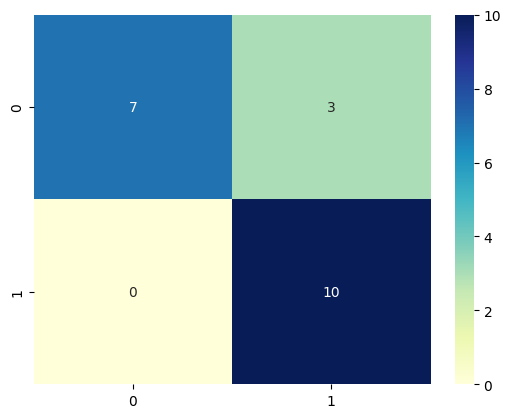

In [71]:
sns.heatmap(
    confusion_matrix(y_test,y_pred),
    cmap = 'YlGnBu',
    annot = True
)

In [73]:
# predict new match

sample = {
    'Toss Won' : 'Yes',
    'Venue' : 'Chennai',
    'Batting Form': 'Good',
    'Recent Form' : 'Strong'
}

sample_df = pd.DataFrame([sample])

for c in sample_df.columns :
  sample_df[c] = encoders[c].transform(sample_df[c])

pred = model.predict(sample_df)
prob = model.predict_proba(sample_df)

print("prediction : " , encoders['Result'].inverse_transform(pred)[0])
print("Probability : " , prob)

prediction :  Win
Probability :  [[0.01103711 0.98896289]]


In [75]:
sample = {
    'Toss Won' : 'Yes',
    'Venue' : 'Chennai',
    'Batting Form': 'Poor',
    'Recent Form' : 'Weak'
}

sample_df = pd.DataFrame([sample])

for c in sample_df.columns :
  sample_df[c] = encoders[c].transform(sample_df[c])

pred = model.predict(sample_df)
prob = model.predict_proba(sample_df)

print("prediction : " , encoders['Result'].inverse_transform(pred)[0])
print("Probability : " , prob)

prediction :  Lose
Probability :  [[0.64219381 0.35780619]]


In [77]:
sample = {
    'Toss Won' : 'Yes',
    'Venue' : 'Mumbai',
    'Batting Form': 'Good',
    'Recent Form' : 'Average'
}

sample_df = pd.DataFrame([sample])

for c in sample_df.columns :
  sample_df[c] = encoders[c].transform(sample_df[c])

pred = model.predict(sample_df)
prob = model.predict_proba(sample_df)

print("prediction : " , encoders['Result'].inverse_transform(pred)[0])
print("Probability : " , prob)

prediction :  Win
Probability :  [[0.0318386 0.9681614]]
